# M04-L05 — Aumento de Dados, Normalização e Balanceamento

Nesta lição você **não troca de arquitetura**. O foco é observar como o tratamento dos dados muda o treinamento da mesma ResNet18.

Regras do laboratório:

1. use o mesmo `dataset_iris` criado na M04-L03;
2. augmentation aleatório aparece **somente em treino**;
3. primeiro observe e formule uma hipótese qualitativa; depois compare quantitativamente;
4. as variantes são comparadas pela **validação**; o teste é usado apenas na configuração final;
5. imagens salvas em `amostras_aumento/` servem apenas para inspeção didática.


## 1. Preparação e retomada da M04-L04

Na M04-L03, você salvou `dataset_iris/{train,val,test}` em `Meu Drive/dados_modulo_04/dataset_iris`. A M04-L04 salvou `resultados_modulo_m04.csv` nessa mesma pasta. Monte **o mesmo Google Drive** na célula abaixo para reutilizar a divisão balanceada e a acurácia da `ResNet18IrisAdaptada`, sem refazer o dataset nem inventar resultados.

Se o Drive não contiver a pasta ou o CSV, a célula solicitará o upload de `dataset_iris.zip` (com a pasta `dataset_iris` dentro) ou do CSV da M04-L04. Execute a avaliação final da M04-L04 antes desta lição para gerar o arquivo de resultados.


In [2]:
from pathlib import Path
import random
import zipfile
import shutil
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from google.colab import drive, files
from torch.utils.data import DataLoader, Subset, WeightedRandomSampler
from torchvision import datasets, transforms
from torchvision.models import resnet18

SEMENTE = 42
random.seed(SEMENTE)
torch.manual_seed(SEMENTE)
drive.mount('/content/drive')
pasta_modulo_drive = Path('/content/drive/MyDrive/dados_modulo_04')
base_dir = pasta_modulo_drive / 'dataset_iris'
if not base_dir.is_dir():
    print('dataset_iris não encontrado no Drive. Envie dataset_iris.zip da M04-L03.')
    enviados = files.upload()
    if 'dataset_iris.zip' not in enviados:
        raise FileNotFoundError('Envie dataset_iris.zip com train, val e test.')
    with zipfile.ZipFile('/content/dataset_iris.zip') as arquivo_zip:
        if any(nome.startswith('/') or '..' in Path(nome).parts for nome in arquivo_zip.namelist()):
            raise ValueError('O ZIP contém caminhos inválidos.')
        arquivo_zip.extractall('/content')
    base_dir = Path('/content/dataset_iris')

classes_esperadas = {'setosa', 'versicolor', 'virginica'}
for particao in ('train', 'val', 'test'):
    pasta = base_dir / particao
    if not pasta.is_dir() or {p.name for p in pasta.iterdir() if p.is_dir()} != classes_esperadas:
        raise FileNotFoundError(f'Confira train/val/test e as três classes em {base_dir}.')

TAMANHO_IMAGEM = (64, 64)
BATCH_SIZE = 16
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Dataset:', base_dir)
print('Dispositivo:', device)

arquivo_resultados = pasta_modulo_drive / 'resultados_modulo_m04.csv'
if not arquivo_resultados.is_file():
    print('resultados_modulo_m04.csv não encontrado no Drive. Envie o CSV da M04-L04.')
    enviados = files.upload()
    if 'resultados_modulo_m04.csv' not in enviados:
        raise FileNotFoundError('Execute a avaliação final da M04-L04 e envie resultados_modulo_m04.csv.')
    arquivo_resultados = Path('/content/resultados_modulo_m04.csv')
resultados_modulo = pd.read_csv(arquivo_resultados)
if not {'modelo', 'acuracia_teste'}.issubset(resultados_modulo.columns):
    raise ValueError('O CSV precisa conter modelo e acuracia_teste.')
if not resultados_modulo['modelo'].astype(str).eq('ResNet18IrisAdaptada').any():
    raise ValueError('O CSV da M04-L04 precisa conter a linha ResNet18IrisAdaptada.')
display(resultados_modulo)


Mounted at /content/drive
Dataset: /content/drive/MyDrive/dados_modulo_04/dataset_iris
Dispositivo: cpu


,modelo,acuracia_teste
0,LogisticRegression,NaN
1,DecisionTreeClassifier,NaN
2,KNeighborsClassifier,NaN
3,MLP escolhida — Mais larga (5→16→3),1.000000
4,MLP escolhida regularizada — Mais larga (5→16→3),1.000000
5,CNNIrisSimples (imagem direta),0.393939
6,AlexNetIrisAdaptada,0.272727
7,ResNet18IrisAdaptada,0.393939
8,ResNet18IrisMelhorada_L05_geometrico,0.545455


### 1.1 Conferindo a continuidade do balanceamento

Na M04-L03, o dataset foi criado usando a quantidade da menor classe. Portanto, esperamos que `dataset_iris/train` tenha quantidades iguais ou muito próximas entre as classes (diferenças de uma unidade podem ocorrer dependendo da divisão).


In [3]:
contagem_atual = []
for pasta in sorted((base_dir / "train").iterdir()):
    if pasta.is_dir():
        qtd = len([p for p in pasta.iterdir() if p.is_file()])
        contagem_atual.append({"classe": pasta.name, "quantidade": qtd})

df_contagem_atual = pd.DataFrame(contagem_atual)
display(df_contagem_atual)


,classe,quantidade
0,setosa,46
1,versicolor,46
2,virginica,46


**Diagnóstico curto:** olhando a tabela acima, o conjunto de trabalho está balanceado? Como isso se conecta ao undersampling realizado na M04-L03?

**Sua resposta:**

Olhando a tabela, podemos ver que o conjunto está balanceado por ter todas as amostras em quantidades iguais. Isso se conecta ao undersampling realizado na M04-L03 quando pensamos que esta tecnica visa justamente corrigir esses desbalanceamento.


## 2. Exemplo guiado 1 — três categorias de aumento e imagens salvas

Antes de executar as transformações, use o diagrama abaixo como mapa das três famílias que serão exploradas no laboratório:

![Três categorias de aumento de dados](https://drive.google.com/thumbnail?id=1GRVHu1eBVymkYpEM3rxqt3dhS9Sr7FRq&sz=w1600)

Observe que uma transformação só é útil se a imagem resultante continuar plausível para a classe. A atividade a seguir permite verificar isso diretamente em uma fotografia real do `dataset_iris`.

Vamos escolher uma fotografia real de `dataset_iris/train` e gerar três versões: geométrica, cor/contraste e distorção leve. Nesta etapa as transformações retornam imagens PIL para que possamos salvá-las diretamente.


salvo: amostras_aumento/original.png
salvo: amostras_aumento/geometrico.png
salvo: amostras_aumento/cor_contraste.png
salvo: amostras_aumento/distorcao.png


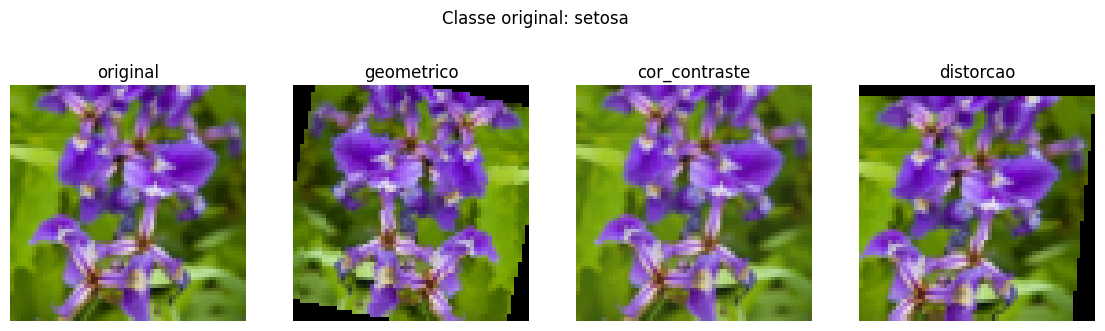

In [4]:
dataset_sem_transform = datasets.ImageFolder(base_dir / "train")
caminho_imagem, rotulo = dataset_sem_transform.samples[0]
imagem_pil = dataset_sem_transform.loader(caminho_imagem)
classe_imagem = dataset_sem_transform.classes[rotulo]

pasta_amostras = Path("amostras_aumento")
pasta_amostras.mkdir(exist_ok=True)

transform_visual_original = transforms.Resize(TAMANHO_IMAGEM)
transform_visual_geometrico = transforms.Compose([
    transforms.Resize(TAMANHO_IMAGEM),
    transforms.RandomRotation(degrees=15),
    transforms.RandomHorizontalFlip(p=1.0),
])
transform_visual_cor = transforms.Compose([
    transforms.Resize(TAMANHO_IMAGEM),
    transforms.ColorJitter(brightness=0.20, contrast=0.20, saturation=0.10),
])
transform_visual_distorcao = transforms.Compose([
    transforms.Resize(TAMANHO_IMAGEM),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.08, 0.08),
        scale=(0.90, 1.10),
        shear=8,
    ),
])

versoes = {
    "original": transform_visual_original(imagem_pil),
    "geometrico": transform_visual_geometrico(imagem_pil),
    "cor_contraste": transform_visual_cor(imagem_pil),
    "distorcao": transform_visual_distorcao(imagem_pil),
}

for nome, imagem in versoes.items():
    caminho_saida = pasta_amostras / f"{nome}.png"
    imagem.save(caminho_saida)
    print("salvo:", caminho_saida)

fig, eixos = plt.subplots(1, 4, figsize=(14, 4))
for eixo, (nome, imagem) in zip(eixos, versoes.items()):
    eixo.imshow(imagem)
    eixo.set_title(nome)
    eixo.axis("off")
plt.suptitle(f"Classe original: {classe_imagem}")
plt.show()


### Exercício 1 — avaliação qualitativa antes do treino

Use este fluxo durante toda a atividade — ele será retomado depois do treinamento:

![Como decidir se um aumento deve ser usado?](https://drive.google.com/thumbnail?id=1zkc2pG7aK4QqVgHjP44mcCt4e7nlkf0a&sz=w1600)

Neste momento você está nas etapas **1 — Observar** e **2 — Formular hipótese**. Registre sua avaliação **antes** de conhecer as métricas.

Abra também os arquivos de `amostras_aumento/` e responda com base **nas imagens que você acabou de gerar**.

| Categoria | O que mudou? | A classe parece preservada? | Parece uma foto plausível? | Eu usaria? |
|---|---|---|---|---|
| Geométrico | A imagem foi rotacionada e invertida verticalmente | Sim, pois a flor continua a mesma, ela apenas foi invertida e inclinada | Sim, o espelhamento ou rotação não alteram a física real da flor | Sim, é o aumento mais comum e seguro para CNNs |
| Cor/contraste | Houve alteração de brilho e saturação da imagem | Sim, pois apenas houve mudança leve no fundo e nas cores da flor | Sim, parece uma foto plausível pois apresenta a mesma flor, apenas havendo mudanças sutis na edição da imagem | Sim, ajuda o modelo a generalizar melhor a iluminação |
| Distorção | A imagem sofreu translação e um leve achatamento também | A pétala sofreu algumas alterações | Acredito que seja apenas plausível se não houverem mudanças drásticas na flor | Apenas se  for bem sútil para não corromper a forma da planta |

Depois registre uma frase: **qual categoria você espera que ajude mais a validação e por quê?**

**Sua resposta:**

Acredito que a categoria geométrica, pois é uma das mais seguras e comuns para as CNNs, apresentando mudanças sutis e realistas.


## 3. Exemplo guiado 2 — combinações progressivas e regra “somente no treino”

O diagrama abaixo antecipa a lógica da próxima exploração: primeiro cada categoria isolada, depois combinações entre elas.

![Aumento progressivo: técnicas isoladas e em combinação](https://drive.google.com/thumbnail?id=191B2QX_gVzliCw4ntOJWRiRu81yPWkLn&sz=w1600)

No notebook, essa mesma ideia será observada com uma fotografia real do dataset, e não apenas com a ilustração.

Antes de criar os pipelines, fixe esta regra:

![Treino pode variar; validação e teste devem permanecer estáveis](https://drive.google.com/thumbnail?id=1XVxFmcFc26Gt8SLsocrO_MWCzci4zCVR&sz=w1600)

As transformações aleatórias pertencem ao **treino**. Validação e teste devem receber um processamento estável, para que a comparação entre experimentos continue sendo justa.

Agora vamos visualizar transformações isoladas e combinações. Depois construiremos pipelines de treino e um pipeline fixo de validação/teste.


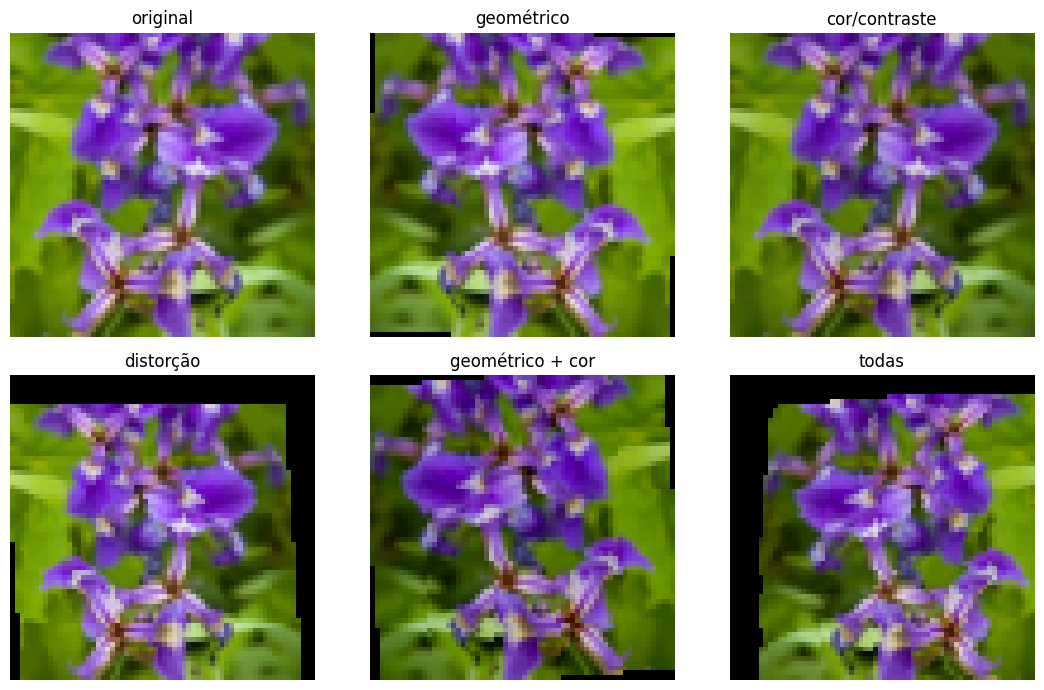

In [5]:
transform_visual_geom_cor = transforms.Compose([
    transforms.Resize(TAMANHO_IMAGEM),
    transforms.RandomRotation(15),
    transforms.RandomHorizontalFlip(p=1.0),
    transforms.ColorJitter(brightness=0.20, contrast=0.20, saturation=0.10),
])
transform_visual_tudo = transforms.Compose([
    transforms.Resize(TAMANHO_IMAGEM),
    transforms.RandomRotation(15),
    transforms.RandomHorizontalFlip(p=1.0),
    transforms.ColorJitter(brightness=0.20, contrast=0.20, saturation=0.10),
    transforms.RandomAffine(degrees=0, translate=(0.08, 0.08), scale=(0.90, 1.10), shear=8),
])

combinacoes = {
    "original": transform_visual_original(imagem_pil),
    "geométrico": transform_visual_geometrico(imagem_pil),
    "cor/contraste": transform_visual_cor(imagem_pil),
    "distorção": transform_visual_distorcao(imagem_pil),
    "geométrico + cor": transform_visual_geom_cor(imagem_pil),
    "todas": transform_visual_tudo(imagem_pil),
}

fig, eixos = plt.subplots(2, 3, figsize=(11, 7))
for eixo, (nome, imagem) in zip(eixos.ravel(), combinacoes.items()):
    eixo.imshow(imagem)
    eixo.set_title(nome)
    eixo.axis("off")
plt.tight_layout()
plt.show()


In [6]:
MEDIA = [0.5, 0.5, 0.5]
DESVIO = [0.5, 0.5, 0.5]

transform_val_teste = transforms.Compose([
    transforms.Resize(TAMANHO_IMAGEM),
    transforms.ToTensor(),
    transforms.Normalize(MEDIA, DESVIO),
])

transform_sem_aumento = transforms.Compose([
    transforms.Resize(TAMANHO_IMAGEM),
    transforms.ToTensor(),
    transforms.Normalize(MEDIA, DESVIO),
])

transform_geometrico = transforms.Compose([
    transforms.Resize(TAMANHO_IMAGEM),
    transforms.RandomRotation(15),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(MEDIA, DESVIO),
])

transform_cor = transforms.Compose([
    transforms.Resize(TAMANHO_IMAGEM),
    transforms.ColorJitter(brightness=0.20, contrast=0.20, saturation=0.10),
    transforms.ToTensor(),
    transforms.Normalize(MEDIA, DESVIO),
])

transform_distorcao = transforms.Compose([
    transforms.Resize(TAMANHO_IMAGEM),
    transforms.RandomAffine(degrees=0, translate=(0.08, 0.08), scale=(0.90, 1.10), shear=8),
    transforms.ToTensor(),
    transforms.Normalize(MEDIA, DESVIO),
])

print("Validação/teste não possuem nenhuma transformação aleatória.")


Validação/teste não possuem nenhuma transformação aleatória.


### Exercício 2 — escolha antes de ver os resultados

Com base apenas na sua inspeção do Exercício 1, altere os três valores booleanos abaixo. Não olhe nenhuma métrica nova antes de decidir.

Depois execute a célula pronta que monta `transform_escolha_qualitativa`.


In [7]:
# ALTERE APENAS True/False com base na sua avaliação qualitativa.
USAR_GEOMETRICO = True
USAR_COR = True
USAR_DISTORCAO = False

operacoes_escolhidas = [transforms.Resize(TAMANHO_IMAGEM)]
if USAR_GEOMETRICO:
    operacoes_escolhidas += [
        transforms.RandomRotation(15),
        transforms.RandomHorizontalFlip(p=0.5),
    ]
if USAR_COR:
    operacoes_escolhidas.append(
        transforms.ColorJitter(brightness=0.20, contrast=0.20, saturation=0.10)
    )
if USAR_DISTORCAO:
    operacoes_escolhidas.append(
        transforms.RandomAffine(degrees=0, translate=(0.08, 0.08), scale=(0.90, 1.10), shear=8)
    )
operacoes_escolhidas += [
    transforms.ToTensor(),
    transforms.Normalize(MEDIA, DESVIO),
]
transform_escolha_qualitativa = transforms.Compose(operacoes_escolhidas)
print(transform_escolha_qualitativa)


Compose(
    Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    RandomHorizontalFlip(p=0.5)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.9, 1.1), hue=None)
    ToTensor()
    Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
)


## 4. Exemplo guiado 3 — o que a normalização muda numericamente

Normalização não cria uma nova variação aleatória. Vamos aplicar `ToTensor()` e depois `Normalize` ao mesmo exemplo para observar a escala dos valores.


In [8]:
so_tensor = transforms.Compose([
    transforms.Resize(TAMANHO_IMAGEM),
    transforms.ToTensor(),
])

tensor_antes = so_tensor(imagem_pil)
tensor_depois = transforms.Normalize(MEDIA, DESVIO)(tensor_antes)

print("Antes -> min={:.3f}, max={:.3f}, média={:.3f}".format(
    tensor_antes.min().item(), tensor_antes.max().item(), tensor_antes.mean().item()
))
print("Depois -> min={:.3f}, max={:.3f}, média={:.3f}".format(
    tensor_depois.min().item(), tensor_depois.max().item(), tensor_depois.mean().item()
))


Antes -> min=0.000, max=0.996, média=0.396
Depois -> min=-1.000, max=0.992, média=-0.208


## 5. Exercício 3 — comparação quantitativa das categorias

A função abaixo mantém arquitetura, semente, otimizador, épocas e validação iguais. A única diferença entre os experimentos é o `transform` aplicado ao treino.

Para manter o laboratório curto, usamos poucas épocas. O objetivo é **comparar o comportamento**, não provar superioridade estatística.


In [9]:
def criar_resnet18_iris():
    modelo = resnet18(weights=None)
    modelo.fc = nn.Linear(modelo.fc.in_features, 3)
    return modelo.to(device)


def treinar_experimento(nome, transform_treino, epocas=10):
    torch.manual_seed(SEMENTE)

    ds_treino = datasets.ImageFolder(base_dir / "train", transform=transform_treino)
    ds_val = datasets.ImageFolder(base_dir / "val", transform=transform_val_teste)

    loader_treino = DataLoader(ds_treino, batch_size=BATCH_SIZE, shuffle=True)
    loader_val = DataLoader(ds_val, batch_size=BATCH_SIZE, shuffle=False)

    modelo = criar_resnet18_iris()
    criterio = nn.CrossEntropyLoss()
    otimizador = optim.Adam(modelo.parameters(), lr=1e-4)

    historico = []
    for epoca in range(1, epocas + 1):
        modelo.train()
        acertos_treino = total_treino = 0
        perda_treino_total = 0.0

        for imagens, rotulos in loader_treino:
            imagens, rotulos = imagens.to(device), rotulos.to(device)
            otimizador.zero_grad()
            saidas = modelo(imagens)
            perda = criterio(saidas, rotulos)
            perda.backward()
            otimizador.step()

            perda_treino_total += perda.item() * imagens.size(0)
            acertos_treino += (saidas.argmax(1) == rotulos).sum().item()
            total_treino += imagens.size(0)

        modelo.eval()
        acertos_val = total_val = 0
        perda_val_total = 0.0
        with torch.no_grad():
            for imagens, rotulos in loader_val:
                imagens, rotulos = imagens.to(device), rotulos.to(device)
                saidas = modelo(imagens)
                perda = criterio(saidas, rotulos)
                perda_val_total += perda.item() * imagens.size(0)
                acertos_val += (saidas.argmax(1) == rotulos).sum().item()
                total_val += imagens.size(0)

        linha = {
            "experimento": nome,
            "epoca": epoca,
            "perda_treino": perda_treino_total / total_treino,
            "acc_treino": acertos_treino / total_treino,
            "perda_val": perda_val_total / total_val,
            "acc_val": acertos_val / total_val,
        }
        historico.append(linha)
        print(nome, linha)

    return modelo, pd.DataFrame(historico)


In [10]:
N_EPOCAS_CURTAS = 10

experimentos = {
    "sem_aumento": transform_sem_aumento,
    "geometrico": transform_geometrico,
    "cor_contraste": transform_cor,
    "distorcao": transform_distorcao,
    "escolha_qualitativa": transform_escolha_qualitativa,
}

modelos_experimentos = {}
historicos = []

for nome, transform_treino in experimentos.items():
    print("\n===", nome, "===")
    modelo, historico = treinar_experimento(nome, transform_treino, epocas=N_EPOCAS_CURTAS)
    modelos_experimentos[nome] = modelo
    historicos.append(historico)

historico_total = pd.concat(historicos, ignore_index=True)
resumo_augmentation = (
    historico_total.groupby("experimento", as_index=False)["acc_val"]
    .max()
    .rename(columns={"acc_val": "melhor_acc_val"})
    .sort_values("melhor_acc_val", ascending=False)
)
resumo_augmentation.to_csv("resultados_augmentation_l05.csv", index=False)
display(resumo_augmentation)



=== sem_aumento ===
sem_aumento {'experimento': 'sem_aumento', 'epoca': 1, 'perda_treino': 1.147079424581666, 'acc_treino': 0.3115942028985507, 'perda_val': 1.102887543042501, 'acc_val': 0.3333333333333333}
sem_aumento {'experimento': 'sem_aumento', 'epoca': 2, 'perda_treino': 0.43589680307153345, 'acc_treino': 0.9202898550724637, 'perda_val': 1.0662243723869325, 'acc_val': 0.36666666666666664}
sem_aumento {'experimento': 'sem_aumento', 'epoca': 3, 'perda_treino': 0.21578486933224444, 'acc_treino': 0.9637681159420289, 'perda_val': 1.041449205080668, 'acc_val': 0.4}
sem_aumento {'experimento': 'sem_aumento', 'epoca': 4, 'perda_treino': 0.12493877868721451, 'acc_treino': 0.9710144927536232, 'perda_val': 1.112686312198639, 'acc_val': 0.3}
sem_aumento {'experimento': 'sem_aumento', 'epoca': 5, 'perda_treino': 0.09355809226416159, 'acc_treino': 0.9710144927536232, 'perda_val': 1.1632086833318074, 'acc_val': 0.4}
sem_aumento {'experimento': 'sem_aumento', 'epoca': 6, 'perda_treino': 0.06297

,experimento,melhor_acc_val
3,geometrico,0.566667
0,cor_contraste,0.533333
2,escolha_qualitativa,0.500000
1,distorcao,0.466667
4,sem_aumento,0.466667


### Interpretação obrigatória

Compare a tabela acima com a previsão que você escreveu antes do treino.

1. Qual categoria teve a maior `melhor_acc_val`?
2. A sua escolha qualitativa ficou acima ou abaixo de `sem_aumento`?
3. Sua hipótese inicial foi confirmada? Cite os valores.
4. Existe alguma transformação que parecia boa visualmente, mas não ajudou a validação nesta execução?

**Sua resposta:**

1. A categoria que teve a maior `melhor_acc_val` foi a categoria gerométrico.
2. A minha escolha qualitativa ficou acima do `sem_aumento`.
3. Sim, foi comprovada, pois o melhor foi o gerométrico.
4. A cor/contraste, acredito que se estivesse False, teríamos um resultado melhor.


## 6. Balanceamento com continuidade — undersampling, oversampling e peso na loss

Antes do código, compare visualmente as três estratégias:

![Oversampling, undersampling e pesos na função de perda](https://drive.google.com/thumbnail?id=1UnxOtsmzDneLF2Wvku9MkNBmX-_Dudm2&sz=w1600)

Repare na diferença conceitual: **oversampling** e **undersampling** alteram a frequência com que exemplos chegam ao treinamento; **pesos na loss** mantêm a amostragem, mas alteram o custo dos erros de cada classe.

O conjunto atual já está balanceado porque a M04-L03 fez undersampling. Para enxergar o efeito das outras estratégias, vamos criar um **Subset temporário de treino** no qual a primeira classe terá menos exemplos. Nenhum arquivo é apagado.


In [11]:
dataset_balance = datasets.ImageFolder(base_dir / "train", transform=transform_sem_aumento)
classes = dataset_balance.classes
alvo_minoritario = 0

indices_por_classe = {
    classe_idx: [i for i, alvo in enumerate(dataset_balance.targets) if alvo == classe_idx]
    for classe_idx in range(len(classes))
}

indices_desequilibrados = []
for classe_idx, indices in indices_por_classe.items():
    if classe_idx == alvo_minoritario:
        manter = max(2, len(indices) // 3)
        indices_desequilibrados.extend(indices[:manter])
    else:
        indices_desequilibrados.extend(indices)

subset_desequilibrado = Subset(dataset_balance, indices_desequilibrados)
alvos_subset = [dataset_balance.targets[i] for i in indices_desequilibrados]

contagem_desequilibrada = pd.Series(alvos_subset).value_counts().sort_index()
df_desequilibrio = pd.DataFrame({
    "classe": classes,
    "quantidade": [int(contagem_desequilibrada.get(i, 0)) for i in range(len(classes))],
})
display(df_desequilibrio)


,classe,quantidade
0,setosa,15
1,versicolor,46
2,virginica,46


In [12]:
# Oversampling por amostragem ponderada
pesos_por_classe = {
    i: 1.0 / int(contagem_desequilibrada[i])
    for i in range(len(classes))
}
pesos_por_amostra = [pesos_por_classe[alvo] for alvo in alvos_subset]

sampler = WeightedRandomSampler(
    weights=pesos_por_amostra,
    num_samples=len(pesos_por_amostra),
    replacement=True,
)
loader_oversampling = DataLoader(
    subset_desequilibrado,
    batch_size=BATCH_SIZE,
    sampler=sampler,
)

contagem_amostrada = {i: 0 for i in range(len(classes))}
for _, rotulos in loader_oversampling:
    for r in rotulos.tolist():
        contagem_amostrada[r] += 1

pd.DataFrame({
    "classe": classes,
    "antes_do_sampler": [int(contagem_desequilibrada[i]) for i in range(len(classes))],
    "amostrado_em_uma_epoca": [contagem_amostrada[i] for i in range(len(classes))],
})


,classe,antes_do_sampler,amostrado_em_uma_epoca
0,setosa,15,35
1,versicolor,46,40
2,virginica,46,32


In [13]:
# Pesos por classe na função de perda: maior peso para a classe menos frequente.
pesos_loss = torch.tensor(
    [1.0 / int(contagem_desequilibrada[i]) for i in range(len(classes))],
    dtype=torch.float32,
)
pesos_loss = pesos_loss / pesos_loss.sum() * len(classes)
criterio_ponderado = nn.CrossEntropyLoss(weight=pesos_loss.to(device))

print("Classes:", classes)
print("Pesos na loss:", pesos_loss)


Classes: ['setosa', 'versicolor', 'virginica']
Pesos na loss: tensor([1.8158, 0.5921, 0.5921])


**Diagnóstico:**

1. Qual classe foi reduzida no `Subset`?
2. Depois do `WeightedRandomSampler`, a distribuição amostrada ficou mais próxima de equilibrada?
3. Qual classe recebeu o maior peso na `CrossEntropyLoss`?
4. Explique, usando as saídas acima, a diferença entre “aparecer mais vezes no batch” e “um erro custar mais”.

**Sua resposta:**

1. A classe `setosa` foi reduzida no `Subset`.
2. De certa forma ficou. Temos números próximos, mas ainda temos uma diferença considerável de 8 amostras entre a menor e a maior.
3. O maior peso foi para a classe `setosa`.
4. A classe que apareceu mais vezes no batch foi a `versicolor`, mas houve um erro na distribuição de pesos (eu acho, fiquei um pouco confusa) e a `setosa`, que estava com uma das menores quantidades de amostras, recebeu o maior peso na loss.

## 7. Exemplo de erro comum — augmentation vazando para o teste

A célula abaixo está **errada de propósito**: ela usa `transform_geometrico` no teste. Como a transformação é aleatória, a mesma avaliação pode receber imagens diferentes.


In [14]:
melhor_nome = resumo_augmentation.iloc[0]["experimento"]
melhor_modelo = modelos_experimentos[melhor_nome]


def avaliar(modelo, loader):
    modelo.eval()
    acertos = total = 0
    with torch.no_grad():
        for imagens, rotulos in loader:
            imagens, rotulos = imagens.to(device), rotulos.to(device)
            saidas = modelo(imagens)
            acertos += (saidas.argmax(1) == rotulos).sum().item()
            total += imagens.size(0)
    return acertos / total

# ERRO PROPOSITAL:
dataset_teste_errado = datasets.ImageFolder(base_dir / "test", transform=transform_geometrico)
loader_teste_errado = DataLoader(dataset_teste_errado, batch_size=BATCH_SIZE, shuffle=False)

print("execução 1:", avaliar(melhor_modelo, loader_teste_errado))
print("execução 2:", avaliar(melhor_modelo, loader_teste_errado))


execução 1: 0.36363636363636365
execução 2: 0.3939393939393939


### Exercício de correção

Faça uma única correção na célula abaixo: troque o transform errado pelo pipeline fixo de validação/teste. Depois execute duas vezes e compare.


In [18]:
# CORRIJA APENAS o argumento transform.
dataset_teste_corrigido = datasets.ImageFolder(
    base_dir / "test",
    transform=transform_,  # TODO: troque pelo transform correto
)
loader_teste_corrigido = DataLoader(dataset_teste_corrigido, batch_size=BATCH_SIZE, shuffle=False)

print("execução 1:", avaliar(melhor_modelo, loader_teste_corrigido))
print("execução 2:", avaliar(melhor_modelo, loader_teste_corrigido))


TypeError: default_collate: batch must contain tensors, numpy arrays, numbers, dicts or lists; found <class 'PIL.Image.Image'>

**Por que essa mudança corrige o problema? Use as duas saídas antes/depois como evidência.**

**Sua resposta:**

*(escreva aqui)*


## 8. Exercício final — diagnóstico dirigido com evidência nova

Escolha **uma** categoria que você aprovou qualitativamente: `geometrico`, `cor_contraste` ou `distorcao`. Na célula pronta abaixo, altere apenas `CATEGORIA` e a intensidade correspondente: `INTENSIDADE_ROTACAO` (15 → 35), `INTENSIDADE_BRILHO` (0.20 → 0.50) ou `INTENSIDADE_SHEAR` (8 → 20). As outras intensidades ficam nos valores originais. O código monta o pipeline visual e o pipeline de treino da categoria escolhida.

Depois compare a nova imagem e a acurácia de validação com o experimento **da mesma categoria** na Seção 5. Não use o conjunto de teste neste exercício.


In [ ]:
# Altere apenas a categoria e a intensidade correspondente.
CATEGORIA = 'geometrico'  # 'geometrico', 'cor_contraste' ou 'distorcao'
INTENSIDADE_ROTACAO = 35   # original: 15
INTENSIDADE_BRILHO = 0.20 # original: 0.20; teste 0.50 se escolher cor_contraste
INTENSIDADE_SHEAR = 8     # original: 8; teste 20 se escolher distorcao

if CATEGORIA == 'geometrico':
    aumento_escolhido = transforms.RandomRotation(INTENSIDADE_ROTACAO)
elif CATEGORIA == 'cor_contraste':
    aumento_escolhido = transforms.ColorJitter(brightness=INTENSIDADE_BRILHO)
elif CATEGORIA == 'distorcao':
    aumento_escolhido = transforms.RandomAffine(degrees=0, shear=INTENSIDADE_SHEAR)
else:
    raise ValueError('Escolha geometrico, cor_contraste ou distorcao.')

transform_forte_visual = transforms.Compose([
    transforms.Resize(TAMANHO_IMAGEM),
    aumento_escolhido,
])
imagem_forte = transform_forte_visual(imagem_pil)
imagem_forte.save(pasta_amostras / f'aumento_forte_{CATEGORIA}.png')
plt.figure(figsize=(4, 4))
plt.imshow(imagem_forte)
plt.title(f'{CATEGORIA}: intensidade alterada')
plt.axis('off')
plt.show()


In [ ]:
transform_forte_treino = transforms.Compose([
    transforms.Resize(TAMANHO_IMAGEM),
    aumento_escolhido,
    transforms.ToTensor(),
    transforms.Normalize(MEDIA, DESVIO),
])

modelo_forte, hist_forte = treinar_experimento(
    f'{CATEGORIA}_mais_forte', transform_forte_treino, epocas=N_EPOCAS_CURTAS,
)
melhor_val_forte = hist_forte['acc_val'].max()
melhor_val_original = resumo_augmentation.loc[
    resumo_augmentation['experimento'] == CATEGORIA, 'melhor_acc_val'
].iloc[0]
print(f'Melhor validação — {CATEGORIA} original:', melhor_val_original)
print(f'Melhor validação — {CATEGORIA} mais forte:', melhor_val_forte)


Responda com base **na nova imagem e nas duas métricas de validação da categoria escolhida**:

1. A transformação mais forte ainda parece plausível para o dataset?
2. A acurácia de validação subiu ou caiu em relação à **mesma categoria** com intensidade original?
3. A evidência quantitativa combina com sua avaliação visual?
4. O que esse teste mostra sobre a ideia de que “mais augmentation é sempre melhor”?

**Sua resposta:**

*(escreva aqui)*


## 9. Avaliação final — usar o teste uma vez

A melhor configuração é escolhida pela validação. Agora avaliamos essa configuração no teste fixo e atualizamos o CSV do módulo.


In [ ]:
melhor_nome = resumo_augmentation.iloc[0]["experimento"]
melhor_modelo = modelos_experimentos[melhor_nome]

dataset_teste = datasets.ImageFolder(base_dir / "test", transform=transform_val_teste)
loader_teste = DataLoader(dataset_teste, batch_size=BATCH_SIZE, shuffle=False)
acc_teste_l05 = avaliar(melhor_modelo, loader_teste)

print("Configuração selecionada pela validação:", melhor_nome)
print("Acurácia de teste final da L05:", acc_teste_l05)

nova_linha = pd.DataFrame({
    "modelo": [f"ResNet18IrisMelhorada_L05_{melhor_nome}"],
    "acuracia_teste": [acc_teste_l05],
})

resultados_modulo = resultados_modulo[
    ~resultados_modulo["modelo"].astype(str).str.startswith("ResNet18IrisMelhorada_L05_")
]
resultados_modulo = pd.concat([resultados_modulo, nova_linha], ignore_index=True)
resultados_modulo.to_csv('resultados_modulo_m04.csv', index=False)
pasta_modulo_drive.mkdir(parents=True, exist_ok=True)
shutil.copy2('resultados_modulo_m04.csv', pasta_modulo_drive / 'resultados_modulo_m04.csv')
print('Tabela atualizada salva em:', pasta_modulo_drive / 'resultados_modulo_m04.csv')
display(resultados_modulo)


### Comparação com a M04-L04

Use a linha `ResNet18IrisAdaptada` carregada de `resultados_modulo_m04.csv` da M04-L04 e compare sua acurácia com a nova linha da L05. A célula inicial confere que essa linha existe.

* houve melhora, piora ou resultado parecido?
* essa comparação prova que o augmentation escolhido é sempre melhor? Por quê?

**Sua resposta:**

*(escreva aqui citando os números observados)*


## 10. Desafio extra opcional — sampler x peso na loss

Sobre o mesmo `subset_desequilibrado`, treine duas versões curtas da ResNet18:

1. `WeightedRandomSampler` + `CrossEntropyLoss()` comum;
2. `shuffle=True` + `CrossEntropyLoss(weight=pesos_loss)`.

Mantenha validação, semente, épocas e otimizador iguais. Compare a acurácia de validação. Não altere `dataset_iris` em disco.

> Este desafio é opcional. Você pode reutilizar a função de treino como referência e adaptar apenas `DataLoader` e critério.


In [ ]:
# Desafio opcional — execute depois das células de oversampling e pesos na loss.
# Mantemos a mesma arquitetura, inicialização, validação e número de épocas.
def treinar_balanceamento(nome, loader_treino_desafio, criterio, epocas=N_EPOCAS_CURTAS):
    torch.manual_seed(SEMENTE)
    modelo = criar_resnet18_iris()
    otimizador = optim.Adam(modelo.parameters(), lr=1e-4)
    loader_val_desafio = DataLoader(
        datasets.ImageFolder(base_dir / 'val', transform=transform_val_teste),
        batch_size=BATCH_SIZE, shuffle=False,
    )
    for epoca in range(epocas):
        modelo.train()
        for imagens, rotulos in loader_treino_desafio:
            imagens, rotulos = imagens.to(device), rotulos.to(device)
            otimizador.zero_grad()
            perda = criterio(modelo(imagens), rotulos)
            perda.backward()
            otimizador.step()
    modelo.eval()
    acertos = total = 0
    with torch.no_grad():
        for imagens, rotulos in loader_val_desafio:
            saidas = modelo(imagens.to(device))
            acertos += (saidas.argmax(1) == rotulos.to(device)).sum().item()
            total += len(rotulos)
    return {'estrategia': nome, 'acc_val': acertos / total}

# A primeira estratégia usa o loader_oversampling já construído na Seção 6.
loader_pesos = DataLoader(subset_desequilibrado, batch_size=BATCH_SIZE, shuffle=True)
resultados_desafio = [
    treinar_balanceamento('sampler', loader_oversampling, nn.CrossEntropyLoss()),
    treinar_balanceamento('pesos_na_loss', loader_pesos, criterio_ponderado),
]
pd.DataFrame(resultados_desafio)


## 11. Reflexão final

Em poucas linhas, responda:

1. sua melhor hipótese qualitativa coincidiu com a melhor validação?
2. qual transformação você descartaria depois de ver as imagens e os números?
3. por que a L03 usou undersampling, enquanto a L05 mostra oversampling e pesos na loss como alternativas?
4. por que uma única execução com poucas épocas não permite afirmar que uma estratégia é universalmente superior?

**Sua resposta:**

*(escreva aqui)*


## 12. Checklist de conclusão

* [ ] Reutilizei o mesmo `dataset_iris` da M04-L03/L04.
* [ ] Confirmei a contagem atual das classes e relacionei com o undersampling anterior.
* [ ] Salvei exemplos geométrico, cor/contraste e distorção em `amostras_aumento/`.
* [ ] Avaliei qualitativamente as imagens antes do treino.
* [ ] Registrei minha escolha de augmentation antes de ver as métricas.
* [ ] Mantive augmentation somente no treino.
* [ ] Apliquei normalização em treino, validação e teste.
* [ ] Rodei os experimentos quantitativos e salvei `resultados_augmentation_l05.csv`.
* [ ] Comparei minha hipótese qualitativa com a validação.
* [ ] Observei oversampling e pesos na loss em um subset controladamente desbalanceado.
* [ ] Corrigi o erro de augmentation no teste.
* [ ] Completei o exercício final com uma nova imagem e uma nova métrica.
* [ ] Avaliei no teste apenas a configuração selecionada pela validação.
* [ ] Atualizei `resultados_modulo_m04.csv`.
* [ ] Preenchi a reflexão final.


## 13. O que entregar

Mantenha salvos:

* este notebook executado;
* a pasta `amostras_aumento/`;
* `resultados_augmentation_l05.csv`;
* `resultados_modulo_m04.csv` atualizado.

Se fizer o desafio extra, mantenha também sua tabela comparando sampler e peso na loss.
